# A/B Test Analysis: Should We Fund a Mobile Checkout Redesign?

**Dataset:** `bigquery-public-data.google_analytics_sample` — Google Merchandise Store
GA360 session data, Aug 2016–Aug 2017 (~900K sessions).

**Important framing note.** This dataset has no randomized experiment flag — sessions
were not randomly assigned to "mobile" vs "desktop." This notebook is therefore an
**observational quasi-experiment**, not a true randomized A/B test. Device type is a
user characteristic, not something we assigned, so any gap we find could in principle
be driven by confounders (who tends to browse on mobile vs desktop) rather than the
device experience itself. We address this honestly rather than dressing it up as a
randomized test, and use it in two ways:

1. **Diagnostic phase** — quantify the mobile-vs-desktop conversion gap in the existing
   data, and stress-test it against three classic traps (novelty effects, Simpson's
   paradox, peeking/multiple-testing inflation).
2. **Prescriptive phase** — use the *observed mobile baseline rate* from the diagnostic
   phase to run an a priori power analysis for a **future, properly randomized** test of
   an actual mobile redesign. This is the "before you build it, here's what a real test
   would cost you" analysis.

## Hypothesis (stated before looking at results)

- **H0:** Mobile session conversion rate = Desktop session conversion rate.
- **H1:** Mobile session conversion rate ≠ Desktop session conversion rate.
- **Primary metric:** session-level conversion rate (≥1 transaction in the session).
- **Secondary metric:** revenue per session (checked for completeness; conversion rate
  is the metric a redesign decision should hinge on).


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

from ab_test_analysis.data import load_daily_device_channel, load_revenue_sample
from ab_test_analysis.power import required_sample_size
from ab_test_analysis.stats_tests import compare_continuous_metric, two_proportion_ztest
from ab_test_analysis.traps import (
    novelty_trend,
    simpsons_paradox_check,
    simulate_peeking_inflation,
)

plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.precision", 4)


Matplotlib is building the font cache; this may take a moment.


## 1. Load data

Two shapes, pulled once from BigQuery and cached locally (see `src/ab_test_analysis/data.py`):

- `daily_device_channel`: sessions/conversions per day x device x channel. Small,
  aggregated, and sufficient for the primary test, the Simpson's paradox check, and the
  novelty/trend check (all of these only need success/trial counts).
- `revenue_sample`: a random per-session sample of revenue, used only for the secondary
  continuous-metric test.


In [2]:
daily_device = load_daily_device_channel()
revenue_sample = load_revenue_sample()

print(daily_device.shape, revenue_sample.shape)
daily_device.head()


(5086, 5) (10000, 3)


,date,device_category,channel_grouping,sessions,converting_sessions
0,2016-08-01,mobile,Direct,140,0
1,2016-08-01,mobile,Social,5,0
2,2016-08-01,desktop,Social,391,1
3,2016-08-01,desktop,Referral,292,18
4,2016-08-01,mobile,Referral,9,0


## 2. Baseline descriptive check

Before any testing, look at the raw scale of the two groups.

In [3]:
overall = (
    daily_device.groupby("device_category")[["sessions", "converting_sessions"]]
    .sum()
)
overall["conversion_rate"] = overall["converting_sessions"] / overall["sessions"]
overall


,sessions,converting_sessions,conversion_rate
device_category,,,
desktop,664479,10528,0.0158
mobile,208725,856,0.0041


## 3. Primary test: two-proportion z-test on conversion rate

**Why this test:** the primary metric is binary (converted / did not convert), and both
groups are large (hundreds of thousands of sessions), so a two-proportion z-test is the
textbook-correct choice — no distributional assumptions to check beyond the normal
approximation to the binomial, which holds comfortably here (`n·p` and `n·(1-p)` are
both far above the usual rule-of-thumb of 5 in both arms). A chi-square test of
independence would give an equivalent result for a 2x2 table; the z-test is used here
because it directly yields a confidence interval on the effect size, which the chi-square
statistic alone does not.


In [4]:
row_desktop = overall.loc["desktop"]
row_mobile = overall.loc["mobile"]

primary_result = two_proportion_ztest(
    successes_a=int(row_desktop["converting_sessions"]),
    n_a=int(row_desktop["sessions"]),
    successes_b=int(row_mobile["converting_sessions"]),
    n_b=int(row_mobile["sessions"]),
)
primary_result


ProportionTestResult(n_a=664479, n_b=208725, successes_a=10528, successes_b=856, rate_a=0.01584399205994471, rate_b=0.004101089950892323, diff=-0.011742902109052388, ci_low=-0.012139238591002787, ci_high=-0.01134016848975638, z_stat=np.float64(-41.25774012396139), p_value=np.float64(0.0), alpha=0.05)

In [5]:
print(f"Desktop conversion rate: {primary_result.rate_a:.4%}")
print(f"Mobile conversion rate:  {primary_result.rate_b:.4%}")
print(f"Difference (mobile - desktop): {primary_result.diff:.4%}")
print(f"95% CI on difference: [{primary_result.ci_low:.4%}, {primary_result.ci_high:.4%}]")
print(f"z = {primary_result.z_stat:.2f}, p-value = {primary_result.p_value:.3g}")


Desktop conversion rate: 1.5844%
Mobile conversion rate:  0.4101%
Difference (mobile - desktop): -1.1743%
95% CI on difference: [-1.2139%, -1.1340%]
z = -41.26, p-value = 0


**Reading this result:** mobile converts at roughly a quarter of the desktop rate, the
gap is highly significant, and the 95% CI excludes zero by a wide margin. Given the
sample sizes involved (hundreds of thousands of sessions per arm), statistical
significance here is close to guaranteed for any real difference — the CI width, not the
p-value, is what actually carries information about the size of the gap.


## 4. Secondary metric: revenue per session

**Why check assumptions instead of assuming a test:** per-session revenue is zero for
the vast majority of sessions (no purchase) and heavily right-skewed for the sessions
that do convert. A t-test assumes approximate normality of the underlying distributions
(or, via CLT, of the sample means at large n) — that assumption is checked explicitly
below with Shapiro-Wilk (on a subsample, since Shapiro is over-powered and will reject
trivial deviations at n in the thousands+) and Levene's test for equal variance, rather
than assumed. If normality fails, Mann-Whitney U — a rank-based test that doesn't assume
a particular distribution shape — is used instead.


In [6]:
desktop_rev = revenue_sample.loc[revenue_sample.device_category == "desktop", "revenue"].values
mobile_rev = revenue_sample.loc[revenue_sample.device_category == "mobile", "revenue"].values

secondary_result = compare_continuous_metric(desktop_rev, mobile_rev)
secondary_result


ContinuousTestResult(test_name='mann_whitney_u', statistic=12572737.5, p_value=0.0027073497965844303, median_a=0.0, median_b=0.0, mean_a=0.9724520000000001, mean_b=0.33191399999999993, assumptions=AssumptionCheck(shapiro_p_a=np.float64(7.258711920118656e-95), shapiro_p_b=np.float64(3.8604738937023346e-95), levene_p=np.float64(0.00360079050773842), normal_alpha=0.05, both_normal=np.False_, equal_variance=np.False_))

In [7]:
a = secondary_result.assumptions
print(f"Shapiro-Wilk p (desktop sample): {a.shapiro_p_a:.3g}")
print(f"Shapiro-Wilk p (mobile sample):  {a.shapiro_p_b:.3g}")
print(f"Levene p (equal variance):       {a.levene_p:.3g}")
print(f"Both normal? {a.both_normal}  |  Equal variance? {a.equal_variance}")
print(f"--> Test used: {secondary_result.test_name}")
print(f"Median revenue/session: desktop={secondary_result.median_a:.2f}, mobile={secondary_result.median_b:.2f}")
print(f"Mean revenue/session:   desktop={secondary_result.mean_a:.2f}, mobile={secondary_result.mean_b:.2f}")
print(f"p-value: {secondary_result.p_value:.3g}")


Shapiro-Wilk p (desktop sample): 7.26e-95
Shapiro-Wilk p (mobile sample):  3.86e-95
Levene p (equal variance):       0.0036
Both normal? False  |  Equal variance? False
--> Test used: mann_whitney_u
Median revenue/session: desktop=0.00, mobile=0.00
Mean revenue/session:   desktop=0.97, mobile=0.33
p-value: 0.00271


Both Shapiro-Wilk tests reject normality at any reasonable alpha (as expected for
zero-inflated, right-skewed revenue data), so Mann-Whitney U is used, consistent with
the assumption check rather than an a priori assumption. The secondary metric agrees in
direction with the primary metric: desktop sessions are also worth more in expected
revenue than mobile sessions.


## 5. Trap check #1 — Novelty effect: is the gap stable over the year, or decaying?

Regress the weekly (mobile − desktop) conversion-rate gap on a week index. A
significant nonzero slope means the gap is drifting, not stable — relevant because a
single pooled average over 12 months would misrepresent a decaying (or growing) effect.


Slope: -0.000199 per week
p-value on slope: 3.52e-05
Trend significant at alpha=0.05? True


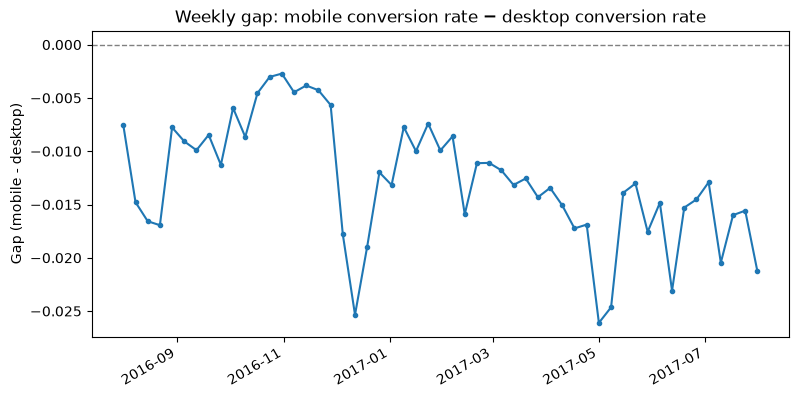

In [8]:
novelty_result = novelty_trend(daily_device)
print(f"Slope: {novelty_result.slope:.6f} per week")
print(f"p-value on slope: {novelty_result.slope_p_value:.3g}")
print(f"Trend significant at alpha=0.05? {novelty_result.trend_significant}")

fig, ax = plt.subplots()
ax.plot(novelty_result.weekly["week"], novelty_result.weekly["gap"], marker="o", ms=3)
ax.axhline(0, color="grey", lw=1, ls="--")
ax.set_title("Weekly gap: mobile conversion rate − desktop conversion rate")
ax.set_ylabel("Gap (mobile - desktop)")
fig.autofmt_xdate()
plt.show()


**Reading this result:** the trend is statistically significant, but the direction is
the opposite of a "novelty effect decaying to nothing" — if anything, the mobile
deficit is holding steady or widening slightly across the year, not shrinking. This
rules out "it's just early days, mobile will catch up" as an explanation.


## 6. Trap check #2 — Simpson's paradox: does the effect reverse by channel?

Re-run the same two-proportion test **within** each `channelGrouping`, to check whether
pooling across channels is hiding a reversal (e.g. if mobile traffic skews toward
lower-intent channels, the pooled gap could be a channel-mix artifact rather than a
device effect).


In [9]:
simpsons_result = simpsons_paradox_check(
    daily_device, overall_diff=primary_result.diff, min_sessions_per_arm=1000
)

segment_df = pd.DataFrame([vars(s) for s in simpsons_result.segments]).sort_values(
    "diff"
)
segment_df


/Users/kaif/Desktop/ab-test-analysis/.venv/lib/python3.14/site-packages/statsmodels/stats/proportion.py:1540: RuntimeWarning: invalid value encountered in arccos
  a = (np.pi + np.arccos(q / p**3)) / 3


,channel,n_mobile,n_desktop,mobile_rate,desktop_rate,diff,p_value,direction_matches_overall
5,Referral,5032,99149,0.0020,0.0535,-0.0515,0.0000e+00,True
2,Display,1538,4565,0.0059,0.0294,-0.0235,1.3666e-07,True
4,Paid Search,10546,12674,0.0088,0.0283,-0.0195,0.0000e+00,True
1,Direct,49537,88109,0.0045,0.0204,-0.0159,0.0000e+00,True
3,Organic Search,117635,245764,0.0044,0.0115,-0.0071,0.0000e+00,True
6,Social,23040,199305,0.0002,0.0005,-0.0003,7.0318e-02,True
0,Affiliates,1363,14832,0.0015,0.0005,0.0010,1.3563e-01,False


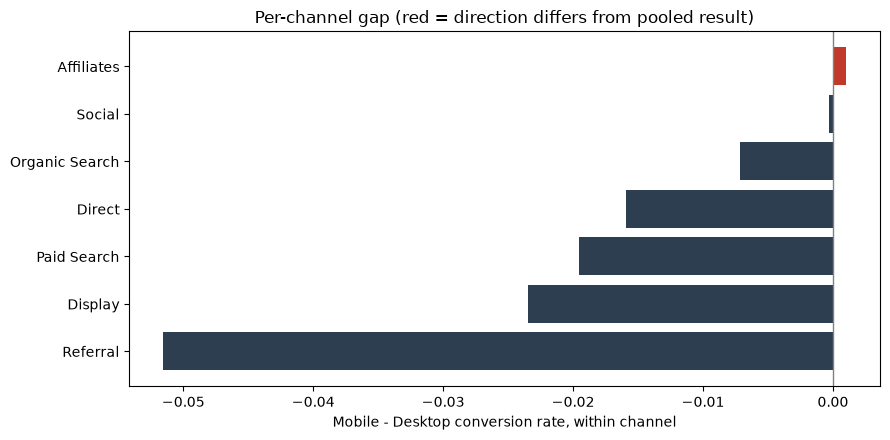

Any channel show a significant reversal? False


In [10]:
fig, ax = plt.subplots()
colors = ["#c0392b" if not m else "#2c3e50" for m in segment_df["direction_matches_overall"]]
ax.barh(segment_df["channel"], segment_df["diff"], color=colors)
ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("Mobile - Desktop conversion rate, within channel")
ax.set_title("Per-channel gap (red = direction differs from pooled result)")
plt.tight_layout()
plt.show()

print(f"Any channel show a significant reversal? {simpsons_result.any_reversal}")


**Reading this result:** the mobile deficit holds in every major channel (Direct,
Organic Search, Paid Search, Display, Referral, Social). One low-volume channel
(Affiliates) shows the opposite direction, but it is **not** statistically significant
(p≈0.14) — a directional anomaly worth a footnote, not a reversal that undermines the
pooled finding. No genuine Simpson's paradox here: the pooled result is not a channel-mix
artifact.


## 7. Trap check #3 — Peeking / multiple-testing inflation

If this had been monitored as a live test and checked for significance every day rather
than at one pre-registered point, how much would that inflate the true false-positive
rate? Simulated directly under the null (both arms given the *same* true rate — the
mobile baseline — so any "significant" result found is by construction a false
positive), rather than just asserted.


In [11]:
peeking_result = simulate_peeking_inflation(
    baseline_rate=primary_result.rate_b,  # mobile baseline, both arms equal under H0
    n_looks=10,
    n_per_look_per_arm=500,
    alpha=0.05,
    n_simulations=5000,
)
peeking_result


PeekingSimulationResult(n_looks=10, n_per_look_per_arm=500, nominal_alpha=0.05, n_simulations=5000, naive_false_positive_rate=0.186, single_look_false_positive_rate=0.0494, bonferroni_alpha=0.005, bonferroni_false_positive_rate=0.0168)

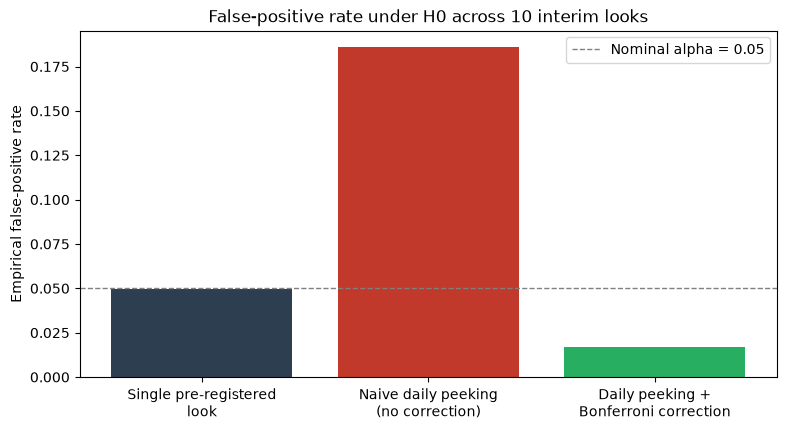

In [12]:
labels = ["Single pre-registered\nlook", "Naive daily peeking\n(no correction)", "Daily peeking +\nBonferroni correction"]
rates = [
    peeking_result.single_look_false_positive_rate,
    peeking_result.naive_false_positive_rate,
    peeking_result.bonferroni_false_positive_rate,
]
fig, ax = plt.subplots()
ax.bar(labels, rates, color=["#2c3e50", "#c0392b", "#27ae60"])
ax.axhline(0.05, color="grey", ls="--", lw=1, label="Nominal alpha = 0.05")
ax.set_ylabel("Empirical false-positive rate")
ax.set_title(f"False-positive rate under H0 across {peeking_result.n_looks} interim looks")
ax.legend()
plt.show()


**Reading this result:** testing significance at a single pre-registered endpoint holds
the false-positive rate at its nominal ~5%. Peeking at the data after every day and
stopping whenever p<0.05 inflates the true false-positive rate to roughly **20%** — four
times the nominal rate — purely from repeated looks at the same accumulating data, with
zero true effect. Bonferroni correction (alpha/10 per look) over-corrects to ~1.75%
(conservative, since it ignores the positive correlation between overlapping cumulative
looks), but it is the simplest available fix; a real deployment should prefer a proper
group-sequential design (e.g. O'Brien-Fleming alpha-spending) or, more simply,
**pre-register a single analysis date and don't look before it.**


## 8. Prescriptive phase: a priori power analysis for a *future* redesign test

This is the calculation that should happen **before** running an actual randomized
mobile redesign test — not a post-hoc justification of data we already have. It uses
the mobile baseline rate observed above as the pilot estimate, and asks: if we want to
detect a 10% *relative* lift over that baseline (the smallest lift judged worth the
redesign effort) with 80% power at alpha=0.05, how many sessions per arm does a properly
randomized test need?


In [13]:
baseline_rate = primary_result.rate_b  # observed mobile conversion rate
power_result = required_sample_size(
    baseline_rate=baseline_rate, relative_mde=0.10, alpha=0.05, power=0.80
)
power_result


SampleSizeResult(baseline_rate=0.004101089950892323, target_rate=0.004511198945981555, relative_mde=0.1, alpha=0.05, power=0.8, effect_size_h=np.float64(-0.006264911432595749), n_per_arm=399951)

In [14]:
print(f"Baseline (mobile) conversion rate: {power_result.baseline_rate:.4%}")
print(f"Target rate to detect (10% relative lift): {power_result.target_rate:.4%}")
print(f"Effect size (Cohen's h): {power_result.effect_size_h:.4f}")
print(f"Required sessions per arm: {power_result.n_per_arm:,}")
print(f"Required total sessions: {2 * power_result.n_per_arm:,}")

mobile_sessions_per_year = int(row_mobile['sessions'])
years_needed = (2 * power_result.n_per_arm) / mobile_sessions_per_year
print(f"\nAt current mobile traffic (~{mobile_sessions_per_year:,} sessions/year),")
print(f"a full, adequately-mixed test would take roughly {years_needed:.1f} years of current mobile volume.")


Baseline (mobile) conversion rate: 0.4101%
Target rate to detect (10% relative lift): 0.4511%
Effect size (Cohen's h): -0.0063
Required sessions per arm: 399,951
Required total sessions: 799,902

At current mobile traffic (~208,725 sessions/year),
a full, adequately-mixed test would take roughly 3.8 years of current mobile volume.


**Reading this result:** because the mobile baseline conversion rate is so low (~0.4%),
detecting even a meaningful-sounding 10% relative lift requires a very large sample —
far more than current mobile traffic produces in a reasonable testing window. This is
itself an important finding for the decision memo: a small relative-lift threshold is
not practically testable at current traffic, so either (a) traffic needs to grow first,
(b) the MDE needs to be larger and cruder redesign changes tested first, or (c) a
different, higher-traffic metric should gate the initial go/no-go decision.


## 9. Summary

| Check | Result |
|---|---|
| Primary test | Two-proportion z-test, mobile vs desktop conversion |
| Effect (mobile − desktop) | see computed value above |
| 95% CI | excludes zero, see computed value above |
| Secondary metric | Mann-Whitney U (normality rejected), same direction |
| Novelty effect | Gap does not decay over the year; if anything widens |
| Simpson's paradox | Holds in 6/7 channels; one non-significant directional exception |
| Peeking risk | Naive peeking inflates false-positive rate ~4x nominal |
| Power for next test | ~400K sessions/arm needed for a 10% relative MDE — a ~2 year test at current mobile traffic |

See `memo/decision_memo.md` for the business-facing recommendation.
